# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1.   Lucas Roldan - 202420931
 2.   
 3.    
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025.csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [ ]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

producto
Cuaderno          20712345
Block de notas    14292347
Resma carta       13133570
Marcador          10020786
Colores x12        9419625
Name: total, dtype: int64


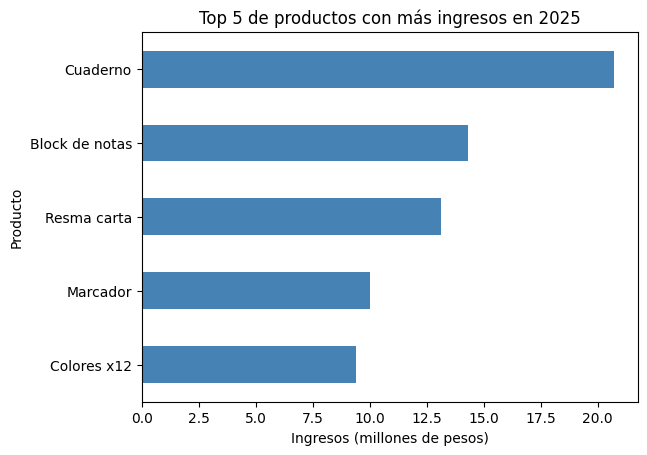

In [ ]:
# Ejercicio 1
# sumamos el total (los ingresos) de cada producto
ingresos_producto = df.groupby("producto")["total"].sum()

# ordenamos de mayor a menor y nos quedamos con los 5 primeros
top_productos = ingresos_producto.sort_values(ascending=False).head(5)
print(top_productos)

# Para la gráfica lo pasamos a millones, si no el eje sale con números muy largos.
# El sort_values() es para que el que más vende quede arriba
(top_productos.sort_values() / 1000000).plot.barh(color="steelblue")
plt.title("Top 5 de productos con más ingresos en 2025")
plt.xlabel("Ingresos (millones de pesos)")
plt.ylabel("Producto")
plt.show()

In [ ]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

ciudad   Bogotá  Medellín
mes                      
1       4815405   3504905
2       3037200   2262080
3       3629385   1342665
4       3117990   1107910
5       3937775   3164730
6       1631810   2848235
7       2781218   2771377
8       3706217   4092446
9       2245001    969551
10      3764217   1745735
11      2623333   1793448
12      2558063   3412380


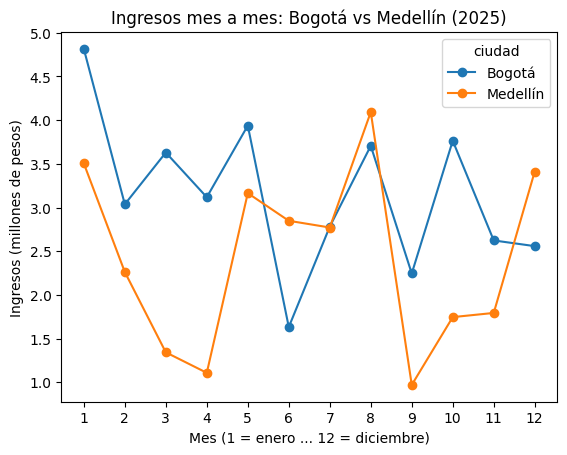

In [ ]:
# Ejercicio 2
# primero dejamos solo las ventas de Bogotá y Medellín
bog_med = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

# tabla dinámica: filas = mes, columnas = ciudad, valores = suma del total
ing_mes_ciudad = pd.pivot_table(bog_med, index="mes", columns="ciudad", values="total", aggfunc="sum")
print(ing_mes_ciudad)

(ing_mes_ciudad / 1000000).plot.line(marker="o")
plt.title("Ingresos mes a mes: Bogotá vs Medellín (2025)")
plt.xlabel("Mes (1 = enero ... 12 = diciembre)")
plt.ylabel("Ingresos (millones de pesos)")
plt.xticks(range(1, 13))   # así salen los 12 meses en el eje
plt.show()

In [ ]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

canal
Online        22887574
Telefónico    61450716
Tienda        34329722
Name: total, dtype: int64


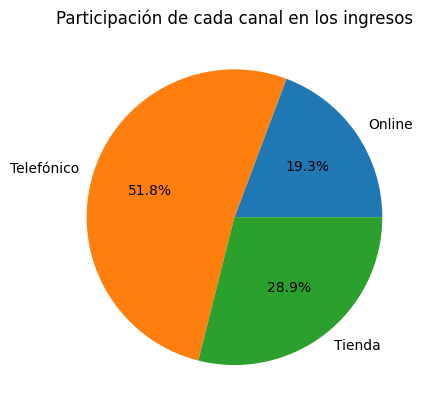

In [ ]:
# Ejercicio 3
ing_canal = df.groupby("canal")["total"].sum()
print(ing_canal)

# autopct="%.1f%%" pone el porcentaje con un decimal en cada tajada
ing_canal.plot.pie(autopct="%.1f%%")
plt.title("Participación de cada canal en los ingresos")
plt.ylabel("")   # pandas deja escrito "total" al lado del pie, lo quitamos
plt.show()

In [ ]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

categoria    Arte  Corrección  Escritura  Organización  Papel
segmento                                                     
Corporativo   2.8         5.4       30.2          23.3   38.2
Mayorista     5.6        12.2       54.0           5.6   22.5
Minorista    12.1        12.8       55.8           4.3   15.2


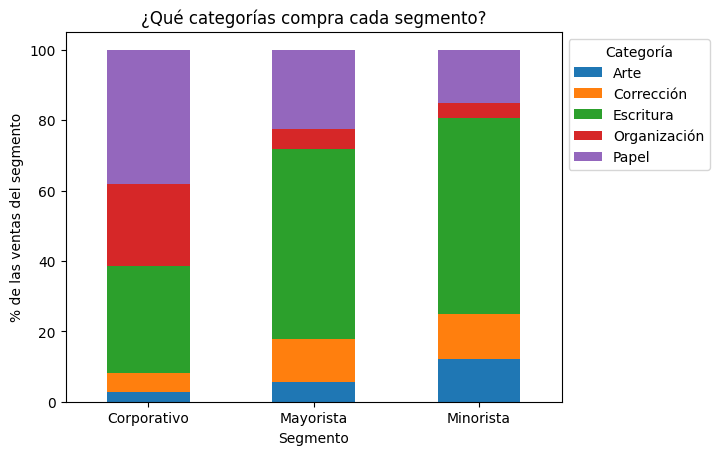

In [ ]:
# Ejercicio 4
# crosstab cuenta cuántas ventas hay de cada segmento en cada categoría.
# Con normalize="index" cada fila queda en proporción (suma 1), por eso se multiplica por 100
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
print(tabla_seg_cat.round(1))

tabla_seg_cat.plot.bar(stacked=True, rot=0)
plt.title("¿Qué categorías compra cada segmento?")
plt.xlabel("Segmento")
plt.ylabel("% de las ventas del segmento")
# la leyenda va afuera, a la derecha, porque adentro tapaba las barras
plt.legend(title="Categoría", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

In [ ]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

           vendedor        ciudad  n_ventas   ticket_prom
0      Andrés Rojas      Medellín       192  60729.104167
1      Camilo Pardo        Bogotá       210  54276.595238
2      Daniela Ríos        Bogotá       130  62903.423077
3     Esteban Uribe      Medellín        94  61833.978723
4      Isabela Mora   Bucaramanga       108  65873.037037
5     Julián Cortés          Cali       215  56389.920930
6       Laura Gómez        Bogotá       312  58564.371795
7        Mateo Peña  Barranquilla       165  60888.484848
8      Paula Vargas          Cali       136  76343.213235
9   Santiago Duarte   Bucaramanga       101  59798.841584
10      Sofía Mejía      Medellín       215  53688.744186
11    Valeria Ortiz  Barranquilla       122  49982.418033


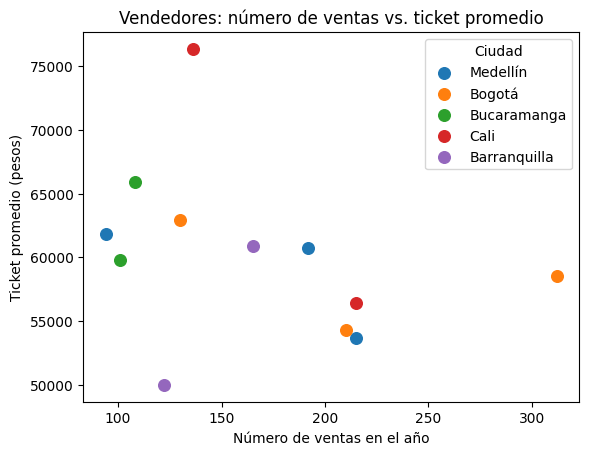

In [ ]:
# Ejercicio 5
# para cada vendedor (con su ciudad) contamos las ventas y sacamos el promedio del total
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
)
vend = vend.reset_index()   # vendedor y ciudad vuelven a ser columnas normales
print(vend)

# Con el for se pintan los vendedores de una ciudad a la vez,
# así cada ciudad queda de un color y sale en la leyenda
for ciudad in vend["ciudad"].unique():
    datos_ciudad = vend[vend["ciudad"] == ciudad]
    plt.scatter(datos_ciudad["n_ventas"], datos_ciudad["ticket_prom"], label=ciudad, s=70)

plt.title("Vendedores: número de ventas vs. ticket promedio")
plt.xlabel("Número de ventas en el año")
plt.ylabel("Ticket promedio (pesos)")
plt.legend(title="Ciudad")
plt.show()

In [ ]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

Ventas del segundo semestre: 1050


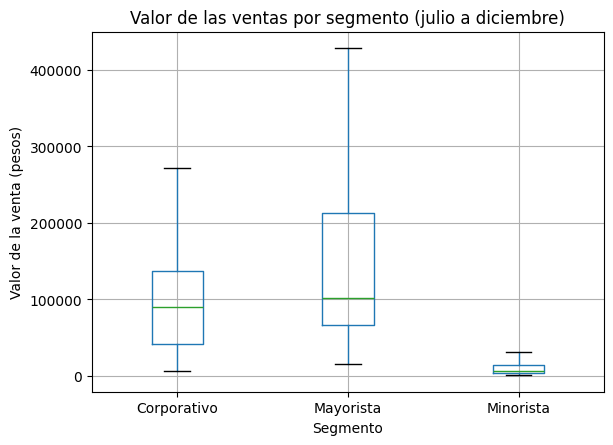

In [ ]:
# Ejercicio 6
# segundo semestre = de julio (mes 7) en adelante
sem2 = df[df["mes"] >= 7]
print("Ventas del segundo semestre:", len(sem2))

sem2.boxplot(column="total", by="segmento", showfliers=False)
plt.title("Valor de las ventas por segmento (julio a diciembre)")
plt.suptitle("")   # quita el título que pandas pone solo arriba ("Boxplot grouped by...")
plt.xlabel("Segmento")
plt.ylabel("Valor de la venta (pesos)")
plt.show()

In [ ]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [ ]:
%%writefile figura_base.py
# Ejercicio 7: los seis gráficos en una figura de 2 filas por 3 columnas
fig, axs = plt.subplots(2, 3, figsize=(16, 9))

# 1. Productos con mayores ingresos
(top_productos.sort_values() / 1_000_000).plot.barh(
    ax=axs[0, 0], color="steelblue")
axs[0, 0].set_title("Ingresos de los cinco productos principales")
axs[0, 0].set_xlabel("Millones de pesos")
axs[0, 0].set_ylabel("")

# 2. Comparación mensual entre Bogotá y Medellín
(ing_mes_ciudad / 1_000_000).plot.line(
    ax=axs[0, 1], marker="o")
axs[0, 1].set_title("Ingresos mensuales: Bogotá y Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Millones de pesos")
axs[0, 1].set_xticks(range(1, 13))

# 3. Participación de cada canal en los ingresos
ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%")
axs[0, 2].set_title("Ingresos por canal")
axs[0, 2].set_ylabel("")

# 4. Categorías de compra por segmento
tabla_seg_cat.plot.bar(
    ax=axs[1, 0], stacked=True, rot=0)
axs[1, 0].set_title("Categorías por segmento")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje")

# 5. Número de ventas y ticket promedio por vendedor
for ciudad in vend["ciudad"].unique():
    datos = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(datos["n_ventas"], datos["ticket_prom"], label=ciudad)
axs[1, 1].set_title("Ventas y ticket promedio por vendedor")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio (pesos)")
axs[1, 1].legend(title="Ciudad", fontsize=8)

# 6. Distribución de las ventas del segundo semestre
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=axs[1, 2])
axs[1, 2].set_title("Valor de las ventas por segmento")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Pesos")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=16)
plt.tight_layout()


Writing figura_base.py


In [ ]:
%run -i figura_base.py

In [ ]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas
La siguiente celda define `mostrar(nombre)`, que ejecuta el archivo `figura_<nombre>.py` y presenta el gráfico. También imprime el código base y las reglas para solicitar cambios a una herramienta de IA.


In [ ]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
# Ejercicio 7: los seis gráficos en una figura de 2 filas por 3 columnas
fig, axs = plt.subplots(2, 3, figsize=(16, 9))

# 1. Productos con mayores ingresos
(top_productos.sort_values() / 1_000_000).plot.barh(
    ax=axs[0, 0], color="steelblue")
axs[0, 0].set_title("Ingresos de los cinco productos principales")
axs[0, 0].set_xlabel("Millones de pesos")
axs[0, 0].set_ylabel("")

# 2. Comparación mensual entre Bogotá y Medellín
(ing_mes_ciudad / 1_000_000).plot.line(
    ax=axs[0, 1], marker="o")
axs[0, 1].set_title("Ingresos mensuales: Bogotá y Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Millones de pesos")
axs[0, 1].set_xticks(range(1, 13))

# 3. Participación de cada canal en los ingresos
ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%")
axs[0, 2].set_title("Ingresos por canal")
axs[0, 2].set_ylabel("")

# 4. Categorías de compra por segmento
tabla_seg_cat.plot.bar(
    ax=axs[1, 0], stacked=True, rot=0)
axs[1, 0].set_

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [ ]:
prompt_v1 = """
Quiero mejorar la presentación de esta figura de seis gráficos sin cambiar los datos ni el tipo de análisis.

PÚBLICO Y OBJETIVO: La figura se presentará en una reunión de la cadena de papelerías para revisar las ventas de 2025. Debe poder leerse sin acercarse demasiado a la pantalla.

PALETA Y TIPOGRAFÍA: Usa fondo blanco, texto gris oscuro y una paleta sencilla. Para la comparación de ciudades utiliza azul para Bogotá y naranja para Medellín. En los demás gráficos usa colores que permitan distinguir las categorías sin recargar la figura. Mantén el mismo tamaño de letra en títulos y ejes.

TÍTULOS: Usa títulos breves que indiquen qué se está comparando, sin adelantar conclusiones que no aparezcan directamente en el gráfico.

EJES Y NÚMEROS: Expresa los ingresos en millones de pesos, conserva los meses en orden y muestra los porcentajes de manera legible.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, utiliza una cuadrícula suave cuando ayude a leer los valores y evita que las leyendas tapen los datos.
"""

print(prompt_v1)


Quiero mejorar la presentación de esta figura de seis gráficos sin cambiar los datos ni el tipo de análisis.

PÚBLICO Y OBJETIVO: La figura se presentará en una reunión de la cadena de papelerías para revisar las ventas de 2025. Debe poder leerse sin acercarse demasiado a la pantalla.

PALETA Y TIPOGRAFÍA: Usa fondo blanco, texto gris oscuro y una paleta sencilla. Para la comparación de ciudades utiliza azul para Bogotá y naranja para Medellín. En los demás gráficos usa colores que permitan distinguir las categorías sin recargar la figura. Mantén el mismo tamaño de letra en títulos y ejes.

TÍTULOS: Usa títulos breves que indiquen qué se está comparando, sin adelantar conclusiones que no aparezcan directamente en el gráfico.

EJES Y NÚMEROS: Expresa los ingresos en millones de pesos, conserva los meses en orden y muestra los porcentajes de manera legible.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, utiliza una cuadrícula suave cuando ayude a leer los valores y evita que las

In [ ]:
%%writefile figura_v1.py
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

fig, axs = plt.subplots(2, 3, figsize=(16, 9))
fig.patch.set_facecolor("white")

# 1. Top 5 de productos
datos = top_productos.sort_values() / 1_000_000
axs[0, 0].barh(datos.index, datos.values, color="steelblue")
axs[0, 0].set_title("Ingresos de los cinco productos principales")
axs[0, 0].set_xlabel("Millones de pesos")

# 2. Bogotá y Medellín por mes
for ciudad, color in [("Bogotá", "steelblue"), ("Medellín", "darkorange")]:
    axs[0, 1].plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad] / 1_000_000,
                   marker="o", color=color, label=ciudad)
axs[0, 1].set_title("Ingresos mensuales: Bogotá y Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Millones de pesos")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].legend(frameon=False)

# 3. Ingresos por canal
ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", startangle=90)
axs[0, 2].set_title("Participación de los canales")
axs[0, 2].set_ylabel("")

# 4. Categorías por segmento
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, rot=0, colormap="Blues")
axs[1, 0].set_title("Categorías por segmento")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje")
axs[1, 0].legend(title="Categoría", fontsize=8, frameon=False)

# 5. Vendedores
for ciudad in vend["ciudad"].unique():
    datos_ciudad = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(datos_ciudad["n_ventas"], datos_ciudad["ticket_prom"],
                      label=ciudad, s=55)
axs[1, 1].set_title("Ventas y ticket promedio por vendedor")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio (pesos)")
axs[1, 1].legend(title="Ciudad", fontsize=7, frameon=False)

# 6. Ventas por segmento en el segundo semestre
sem2.boxplot(column="total", by="segmento", showfliers=False, ax=axs[1, 2])
axs[1, 2].set_title("Valor de las ventas por segmento")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Pesos")

for ax in axs.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=16)
plt.tight_layout()


Writing figura_v1.py


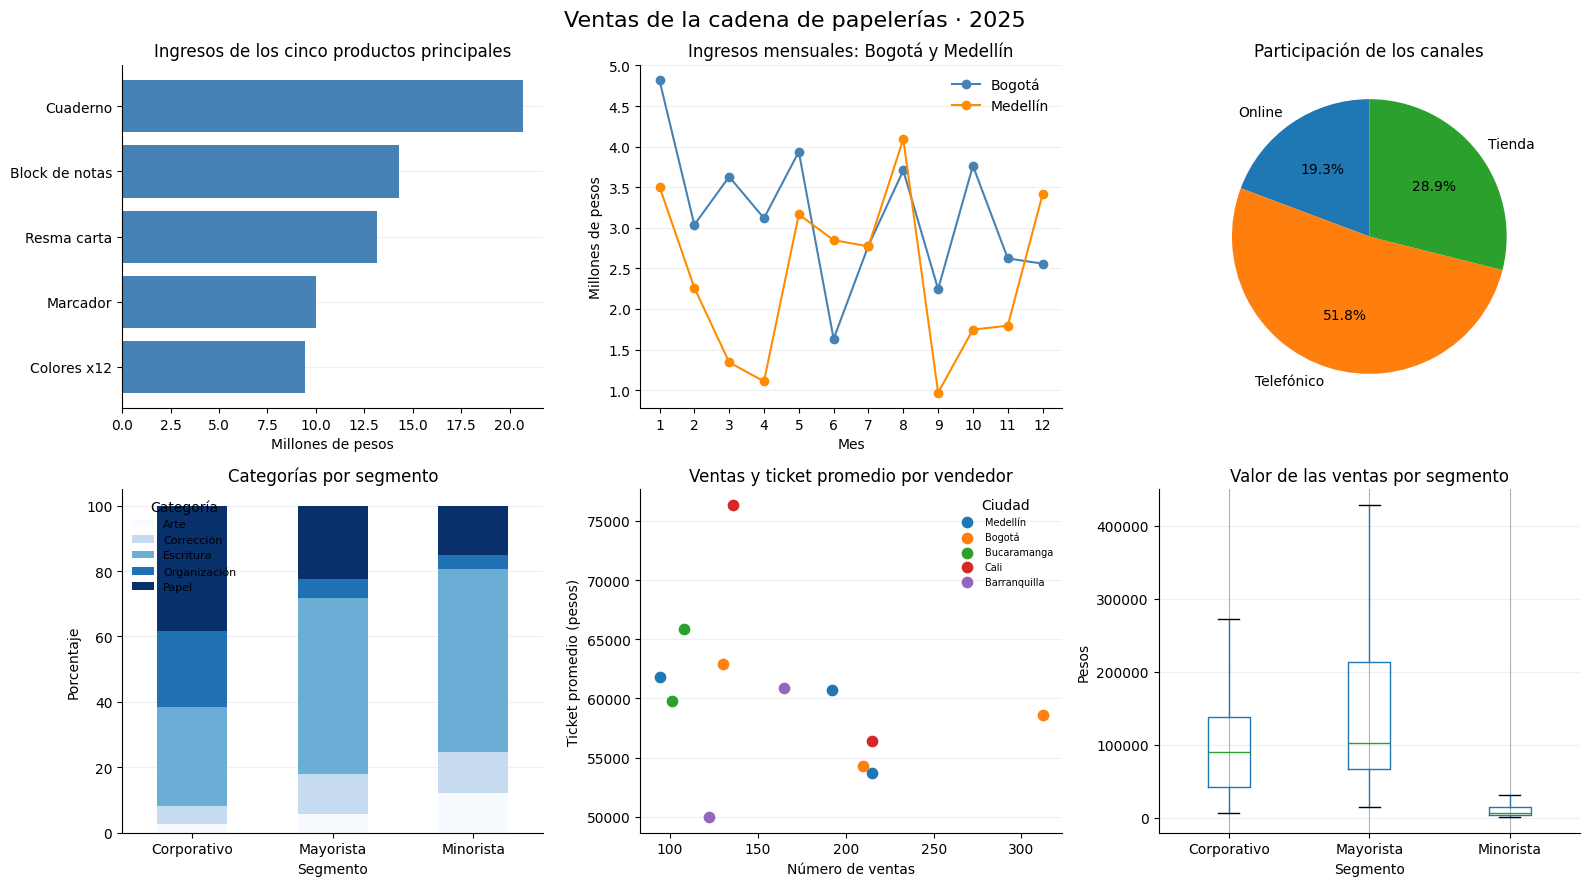

In [ ]:
mostrar("v1")

### Ejercicio 9 · Segunda versión

Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

Rta:
Al revisar la primera figura identificamos problemas de contraste y de espacio en algunas etiquetas. En el segundo prompt pedimos cambios puntuales: una dona para los canales, colores más diferenciables en las barras apiladas, nombres de vendedores y medianas en el diagrama de cajas.

Después de pegar el código de la segunda respuesta, revisamos que se conservaran las seis visualizaciones y los mismos datos.


In [ ]:
prompt_v2 = prompt_v1 + """

AJUSTES: Al revisar la primera versión encontramos algunos detalles que dificultaban la lectura:
1. En el gráfico de productos, los valores del eje se veían apretados. Dejemos el valor al final de cada barra y retiremos ese eje.
2. En el gráfico de canales, los porcentajes no contrastaban bien. Cambiemos el pie por una dona y dejemos el porcentaje en blanco.
3. En las barras apiladas, los tonos de azul eran demasiado parecidos. Usemos colores distintos y suaves.
4. En la dispersión, agreguemos el nombre de cada vendedor cerca de su punto, con letra pequeña.
5. En el boxplot, quitemos el título automático que aparece encima y mostremos la mediana de cada segmento.
"""

print(prompt_v2)


Quiero mejorar la presentación de esta figura de seis gráficos sin cambiar los datos ni el tipo de análisis.

PÚBLICO Y OBJETIVO: La figura se presentará en una reunión de la cadena de papelerías para revisar las ventas de 2025. Debe poder leerse sin acercarse demasiado a la pantalla.

PALETA Y TIPOGRAFÍA: Usa fondo blanco, texto gris oscuro y una paleta sencilla. Para la comparación de ciudades utiliza azul para Bogotá y naranja para Medellín. En los demás gráficos usa colores que permitan distinguir las categorías sin recargar la figura. Mantén el mismo tamaño de letra en títulos y ejes.

TÍTULOS: Usa títulos breves que indiquen qué se está comparando, sin adelantar conclusiones que no aparezcan directamente en el gráfico.

EJES Y NÚMEROS: Expresa los ingresos en millones de pesos, conserva los meses en orden y muestra los porcentajes de manera legible.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, utiliza una cuadrícula suave cuando ayude a leer los valores y evita que las

In [ ]:
%%writefile figura_v2.py
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Colores utilizados en la figura
azul = "#416a9c"
naranja = "#e28b45"
colores_ciudad = {"Bogotá": azul, "Medellín": naranja,
                  "Cali": "#6f9e78", "Barranquilla": "#c4a24d",
                  "Bucaramanga": "#8b79a8"}
colores_categoria = ["#8fb4d8", "#e6b878", "#91b69b", "#c58fa5", "#aaa3c8"]

fig, axs = plt.subplots(2, 3, figsize=(16, 9))
fig.patch.set_facecolor("white")

# 1. Ingresos de los cinco productos principales
datos = top_productos.sort_values() / 1_000_000
axs[0, 0].barh(datos.index, datos.values, color="#8fb0d1")
axs[0, 0].barh(datos.index[-1], datos.values[-1], color=azul)
for i, valor in enumerate(datos.values):
    axs[0, 0].text(valor + 0.15, i, f"$ {valor:.1f} M".replace(".", ","),
                   va="center", fontsize=8)
axs[0, 0].set_xlim(0, datos.max() * 1.35)
axs[0, 0].set_title("Ingresos de los cinco productos principales")
axs[0, 0].set_xlabel("Millones de pesos")
axs[0, 0].xaxis.set_visible(False)
axs[0, 0].grid(False)

# 2. Ingresos mensuales de Bogotá y Medellín
for ciudad in ["Bogotá", "Medellín"]:
    axs[0, 1].plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad] / 1_000_000,
                   marker="o", linewidth=2, color=colores_ciudad[ciudad], label=ciudad)
axs[0, 1].set_title("Ingresos mensuales: Bogotá y Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Millones de pesos")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                           "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"], fontsize=8)
axs[0, 1].legend(frameon=False, fontsize=8)

# 3. Participación de los canales: gráfica de dona
colores_canal = {"Online": "#9bb7d4", "Telefónico": azul, "Tienda": naranja}
porcentajes = [f"{x:.1f}%".replace(".", ",") for x in
               (ing_canal / ing_canal.sum() * 100)]
axs[0, 2].pie(ing_canal.values, labels=ing_canal.index,
              colors=[colores_canal[c] for c in ing_canal.index],
              startangle=90, counterclock=False,
              autopct="%.1f%%", pctdistance=0.78,
              wedgeprops={"width": 0.42, "edgecolor": "white"},
              textprops={"fontsize": 8})
for texto in axs[0, 2].texts:
    if "%" in texto.get_text():
        texto.set_color("white")
        texto.set_fontweight("bold")
axs[0, 2].text(0, 0.05, f"$ {ing_canal.sum()/1_000_000:.1f} M".replace(".", ","),
               ha="center", va="center", fontsize=13, fontweight="bold")
axs[0, 2].text(0, -0.17, "Ingresos 2025", ha="center", fontsize=8)
axs[0, 2].set_title("Participación de los canales")

# 4. Porcentaje de categorías dentro de cada segmento
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, rot=0,
                       color=colores_categoria, edgecolor="white", width=0.65)
axs[1, 0].set_title("Categorías por segmento")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje")
axs[1, 0].yaxis.set_major_formatter(mticker.PercentFormatter())
axs[1, 0].legend(title="Categoría", fontsize=7, frameon=False,
                 loc="upper left", bbox_to_anchor=(1, 1))

# 5. Número de ventas y ticket promedio por vendedor
for ciudad in vend["ciudad"].unique():
    datos_ciudad = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(datos_ciudad["n_ventas"], datos_ciudad["ticket_prom"],
                      color=colores_ciudad[ciudad], label=ciudad, s=48)
# Los nombres se ubican cerca de cada punto; se alterna la altura para facilitar la lectura.
posiciones = {
    "Esteban Uribe": (4, -10),
    "Santiago Duarte": (4, -10),
    "Valeria Ortiz": (4, -10),
    "Sofía Mejía": (4, 8),
    "Julián Cortés": (4, 8),
    "Mateo Peña": (4, -11),
    "Camilo Pardo": (-38, -10),
    "Laura Gómez": (-42, 8),
}
for _, fila in vend.iterrows():
    desplazamiento = posiciones.get(fila["vendedor"], (4, 7))
    axs[1, 1].annotate(fila["vendedor"],
                       (fila["n_ventas"], fila["ticket_prom"]),
                       xytext=desplazamiento, textcoords="offset points",
                       fontsize=6.5)
axs[1, 1].set_title("Ventas y ticket promedio por vendedor")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio (pesos)")
axs[1, 1].yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, pos: f"$ {x/1000:.0f} mil"))
axs[1, 1].legend(title="Ciudad", fontsize=6, frameon=False, loc="upper right")

# 6. Distribución del valor de las ventas por segmento
segmentos = sorted(sem2["segmento"].unique())
valores = [sem2.loc[sem2["segmento"] == s, "total"] for s in segmentos]
cajas = axs[1, 2].boxplot(valores, showfliers=False, patch_artist=True,
                          tick_labels=segmentos, medianprops={"color": "#333333", "linewidth": 2})
for caja, color in zip(cajas["boxes"], ["#9bb7d4", "#e6b878", "#91b69b"]):
    caja.set_facecolor(color)
for i, serie in enumerate(valores, start=1):
    mediana = serie.median()
    axs[1, 2].text(i + 0.16, mediana, f"$ {mediana/1000:.0f} mil",
                   ha="left", va="center", fontsize=7)
axs[1, 2].set_title("Valor de las ventas por segmento")
axs[1, 2].set_xlabel("Segmento (julio a diciembre)")
axs[1, 2].set_ylabel("Valor de la venta")
axs[1, 2].yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, pos: f"$ {x/1000:.0f} mil"))

# Ajustes generales para que los seis gráficos mantengan el mismo estilo.
for ax in axs.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=8)
    ax.set_axisbelow(True)
    if ax not in [axs[0, 0], axs[0, 2]]:
        ax.grid(axis="y", alpha=0.2)

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])


Writing figura_v2.py


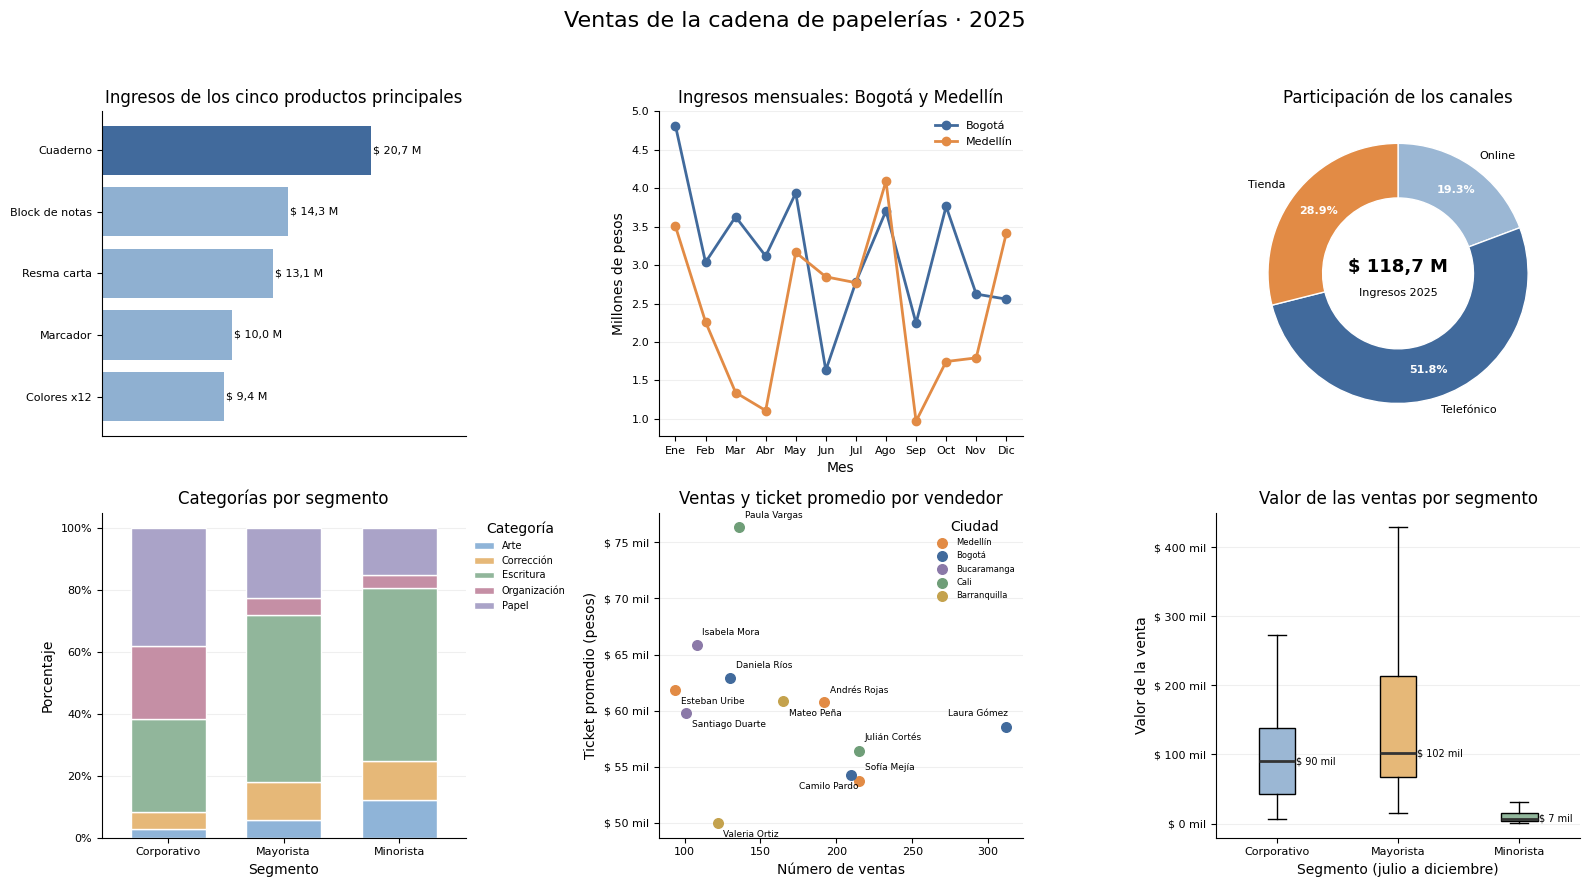

In [ ]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [ ]:
# El ejercicio 10 es opcional. No se desarrolló una tercera versión.


**Ejercicio 10 (opcional):** no se realizó una tercera iteración. La versión seleccionada para la entrega es `v2`.


In [ ]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [ ]:
figura_elegida = "v2"

hallazgos = [
    "El canal Telefónico representó el 51,8 % de los ingresos, con $ 61,45 millones de un total de $ 118,67 millones.",
    "Cuaderno fue el producto con mayores ingresos ($ 20,71 millones), seguido por Block de notas ($ 14,29 millones).",
    "Bogotá registró $ 37,85 millones y Medellín $ 29,02 millones; Bogotá tuvo mayores ingresos en 9 de los 12 meses.",
]


In [ ]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

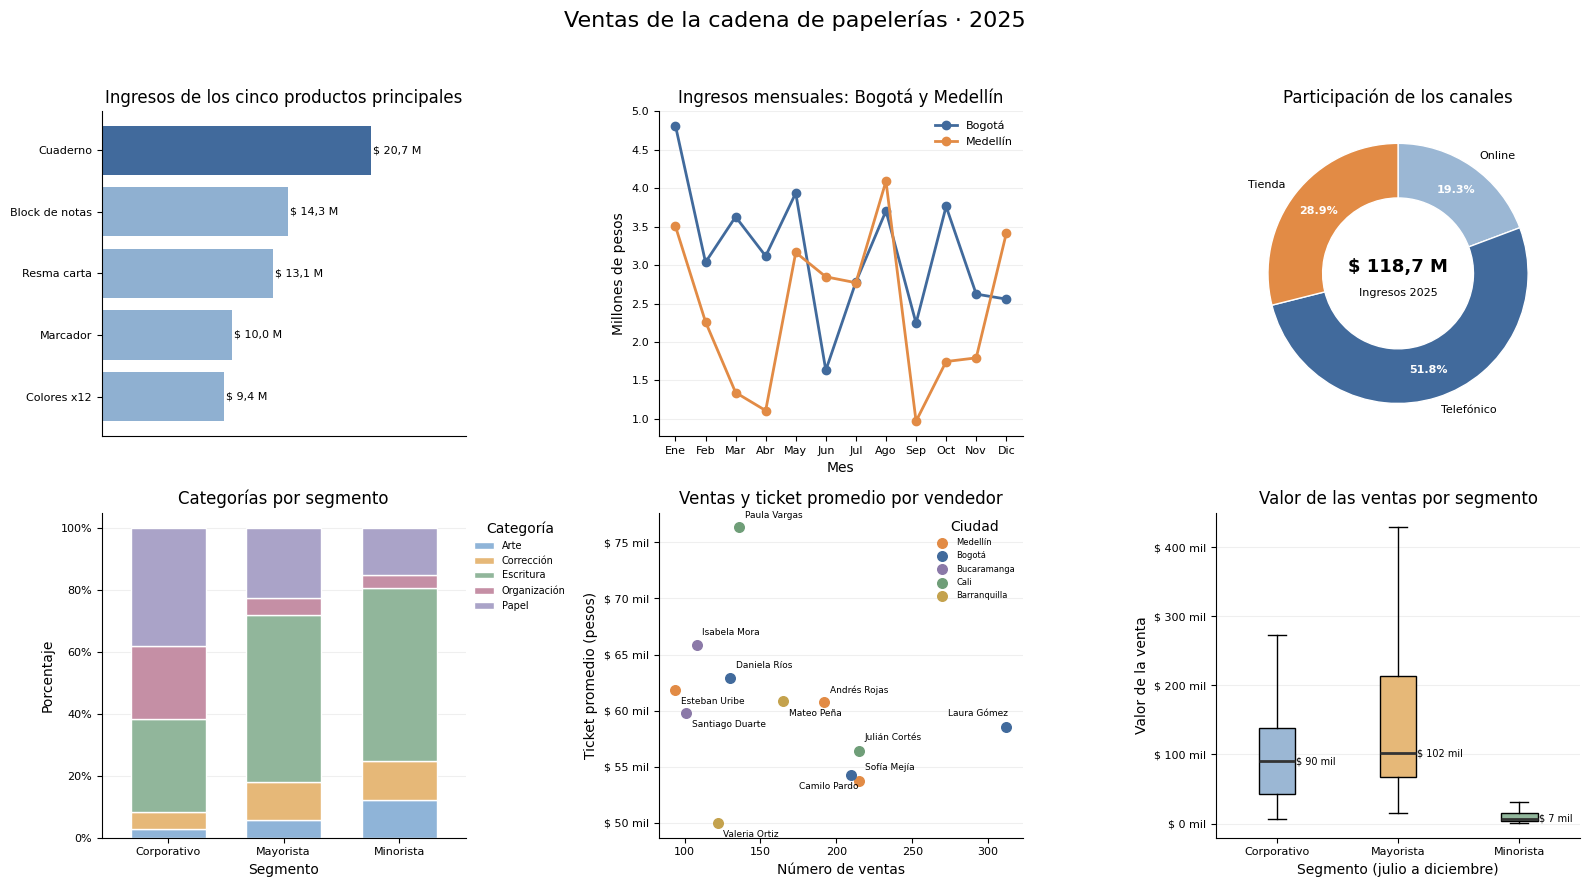

Principales resultados:
• El canal Telefónico representó el 51,8 % de los ingresos, con $ 61,45 millones de un total de $ 118,67 millones.
• Cuaderno fue el producto con mayores ingresos ($ 20,71 millones), seguido por Block de notas ($ 14,29 millones).
• Bogotá registró $ 37,85 millones y Medellín $ 29,02 millones; Bogotá tuvo mayores ingresos en 9 de los 12 meses.


In [ ]:
mostrar(figura_elegida)

print("Principales resultados:")
for h in hallazgos:
    print("•", h)


### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.

### Cambios realizados durante la construcción del dashboard

1. En la primera versión, los valores del gráfico de productos se veían apretados y los porcentajes del gráfico circular tenían poco contraste. Con un promt, pedimos retirar el eje horizontal del primer gráfico y cambiar el pie por una dona con porcentajes en blanco.

2. En las barras apiladas, los tonos de azul eran difíciles de diferenciar. Solicitamos usar colores distintos y suaves. También pedimos quitar el título automático del diagrama de cajas y mostrar la mediana de cada segmento.

3. En el gráfico de dispersión, los nombres de los vendedores no se distinguían bien. Pedimos incluirlos junto a los puntos y luego revisamos visualmente su ubicación. Finalmente, comparamos los resultados con las tablas de los ejercicios anteriores para comprobar que los datos no cambiaran.

**Uso de IA:** Gemini se utilizó para proponer cambios en cuanto al diseño de los gráficos y presentación en general.No obstante, entre todo definimos los ajustes, se revisó el resultado y se verificó las cifras con las tablas construidas en el notebook. Por último, se utilizó además para apoyo en redacción en ciertas celdas y estructura literaria.

**Enlace del notebook en GitHub:** https://github.com/Luc4sRoldan/mi-dashboard-venta/blob/main/Taller%20Graficos%20Publicacion%20Lucas%20Roldan.ipynb